# Fake News Detection on IFND
## Student 3: Word Embedding with BiLSTM
**Approach:** deep learning. **Expected outcome:** a model that learns contextual and sequential text patterns.

Choose **Runtime > Change runtime type > T4 GPU**, then **Runtime > Run all**. Training takes a few minutes.

In [1]:
import numpy as np
try:
    import tensorflow as tf
except ImportError:
    %pip install -q tensorflow
    import tensorflow as tf
import keras

SEED = 42
keras.utils.set_random_seed(SEED)
print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU') or 'not available')

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Load IFND and create the shared partitions
This cell downloads IFND from the authors' repository and creates the 70/15/15 train, validation and test partitions shared by all four students. It stops with an error if the file or partitions differ.

Cleaning applied before partitioning: repair broken text encoding, remove headlines shorter than three words, remove headlines that appear with both labels, and keep one copy of each repeated headline.

Only the headline (`Statement`) is used as input. `Web` and `Category` almost reveal the label directly (for example, every `MISLEADING` row is fake), so using them would inflate the results.

In [2]:
# SHARED CELL - keep identical in all four notebooks so the partitions stay identical.
import hashlib, os, re, urllib.request
import pandas as pd

DATA_URL = ('https://raw.githubusercontent.com/sonalgarg174/Dataset/'
            'f47d8407595c288d2a9c4f0f74a5e721a11995b8/IFND.csv')  # authors' repo, pinned commit
DATA_PATH = 'IFND.csv'
FILE_SHA256 = '3728c7b785ea93c9dadcc61a4c549c0eddd71a5fb6a1a31be08b5235ee4f5bfa'
SPLIT_FINGERPRINT = 'd17a2299ad1e64b524d50ac41e3b9828308b4c483a80ced900d85fc913777544'

if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
with open(DATA_PATH, 'rb') as f:
    assert hashlib.sha256(f.read()).hexdigest() == FILE_SHA256, 'IFND.csv differs from the agreed file'

raw = pd.read_csv(DATA_PATH, encoding='latin-1', dtype=str, keep_default_na=False)

# The file mixes several broken encodings. Restore apostrophes and drop the remaining debris,
# otherwise a model can learn the scraper's encoding instead of the news content.
APOSTROPHES = ['\x92', '\xd5', '\x89\xdb\xaa', '\xe2\x80\x99', '\xef\xbf\xbd']

def repair_text(text):
    for broken in APOSTROPHES:
        text = text.replace(broken, "'")
    text = re.sub(r'[^\x00-\x7f]+', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

df = pd.DataFrame({
    'id': raw['id'],
    'text': raw['Statement'].map(repair_text),
    'label': raw['Label'].str.strip().str.lower().map({'fake': 1, 'true': 0}),  # Fake = 1, Real = 0
    'source': raw['Web'].str.strip().str.upper(),
})
df['key'] = df['text'].str.lower().str.replace(r'[^a-z0-9]+', ' ', regex=True).str.strip()

rows_loaded = len(df)
df = df[df['key'].str.split().str.len() >= 3]                      # too short to classify
df = df[df.groupby('key')['label'].transform('nunique') == 1]      # same headline, both labels
df = df.drop_duplicates('key').copy()                              # a repeat must not span partitions

# Partition: sort each class by a hash of the headline, then cut 70/15/15. This is a reproducible
# stratified shuffle that does not depend on the installed numpy or scikit-learn version.
df['hash'] = df['key'].map(lambda k: hashlib.sha256(k.encode()).hexdigest())
df = df.sort_values('hash').reset_index(drop=True)
rank = df.groupby('label').cumcount()
size = df.groupby('label')['label'].transform('size')
df['split'] = 'test'
df.loc[rank < (size * 0.85).astype(int), 'split'] = 'val'
df.loc[rank < (size * 0.70).astype(int), 'split'] = 'train'

# Flags used only for the robustness check at the end, never as model inputs.
GIVEAWAY = (r'\b(fact check|factcheck|fake|false|falsely|viral|claim|claims|claimed|misleading|hoax|'
            r'rumou?r|debunk|no this|not a|shared as|shared with|morphed|doctored|old video|old photo|'
            r'video|photo|image|picture)\b')
df['is_augmented'] = df['source'].eq('AUGMENT')
df['has_giveaway'] = df['key'].str.contains(GIVEAWAY.replace('(', '(?:'), regex=True)

fingerprint = hashlib.sha256('\n'.join(df['hash'] + df['split']).encode()).hexdigest()
if SPLIT_FINGERPRINT.startswith('__'):
    print('Fingerprint not pinned yet')
else:
    assert fingerprint == SPLIT_FINGERPRINT, 'Partitions differ from the agreed partitions'

train_df = df[df['split'] == 'train'].reset_index(drop=True)
val_df = df[df['split'] == 'val'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)

print(f'Rows loaded {rows_loaded:,} | usable after cleaning {len(df):,}')
print('Partition fingerprint:', fingerprint[:16])
print(df.groupby('split')['label'].agg(rows='size', fake='sum', fake_share='mean').round(3))

Rows loaded 56,714 | usable after cleaning 47,892
Partition fingerprint: d17a2299ad1e64b5
        rows   fake  fake_share
split                          
test    7185   2350       0.327
train  33523  10964       0.327
val     7184   2350       0.327


## 2. Shared evaluation
Accuracy, precision, recall and F1 are computed the same way in every notebook. **Fake is the positive class**, so recall means the share of fake headlines that were caught. (The dataset's README describes 1 as true news, while the CSV itself uses `TRUE` and `Fake`; this project sets Fake = 1.)

In [3]:
# SHARED CELL - the same evaluation for all four approaches.
import json
import matplotlib.pyplot as plt
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, precision_score, recall_score)

def compute_metrics(y_true, y_pred):
    """Precision, recall and F1 treat Fake (1) as the positive class."""
    return {'accuracy': accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred, zero_division=0),
            'f1': f1_score(y_true, y_pred, zero_division=0)}

def evaluate_on_test(y_pred, title):
    y_true = test_df['label'].values
    print(classification_report(y_true, y_pred, target_names=['Real', 'Fake'], digits=4))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=['Real', 'Fake'],
                                            cmap='Blues', values_format=',d')
    plt.title(title)
    plt.show()
    return compute_metrics(y_true, y_pred)

def robustness_check(y_pred):
    """Same predictions, scored on harder parts of the test partition."""
    subsets = {'All test headlines': pd.Series(True, index=test_df.index),
               'Excluding synthetic (AUGMENT)': ~test_df['is_augmented'],
               'Without giveaway words': ~test_df['has_giveaway'],
               'Neither synthetic nor giveaway': ~test_df['is_augmented'] & ~test_df['has_giveaway']}
    rows = []
    for name, mask in subsets.items():
        scores = compute_metrics(test_df.loc[mask, 'label'], y_pred[mask.values])
        rows.append({'subset': name, 'rows': int(mask.sum()),
                     'fake_rows': int(test_df.loc[mask, 'label'].sum()), **scores})
    return pd.DataFrame(rows).set_index('subset').round(4)

def save_results(student, algorithm, y_pred, test_metrics, robustness, details):
    os.makedirs('results', exist_ok=True)
    report = {'student': student, 'algorithm': algorithm, 'partition_fingerprint': fingerprint,
              'test_metrics': test_metrics, 'robustness': robustness.reset_index().to_dict('records'),
              'details': details}
    with open(f'results/student_{student}_metrics.json', 'w') as f:
        json.dump(report, f, indent=2, default=str)
    pd.DataFrame({'id': test_df['id'], 'label': test_df['label'], 'prediction': y_pred}).to_csv(
        f'results/student_{student}_test_predictions.csv', index=False)
    print('Saved to the results folder')

## 3. Text cleaning and tokenization
Headlines are lowercased and split into word tokens. Stopwords stay because word order and words like `not` matter to a sequence model.

In [4]:
from collections import Counter

def tokenize(text):
    return re.findall(r"[a-z0-9']+", text.lower())

train_tokens = train_df['text'].map(tokenize)
val_tokens = val_df['text'].map(tokenize)
test_tokens = test_df['text'].map(tokenize)

print('Before:', train_df['text'][0])
print('After: ', train_tokens[0])
print('Headline length, 99th percentile:', int(train_tokens.str.len().quantile(0.99)), 'tokens')

Before: What happened in the dark of Friday night as BJP pulled off a coup in Maharashtra: A timeline
After:  ['what', 'happened', 'in', 'the', 'dark', 'of', 'friday', 'night', 'as', 'bjp', 'pulled', 'off', 'a', 'coup', 'in', 'maharashtra', 'a', 'timeline']
Headline length, 99th percentile: 32 tokens


## 4. Numerical sequences and padding
The vocabulary comes from the training partition only. Index 0 is reserved for padding and index 1 for unknown words. Every sequence is padded or cut to the same length.

In [5]:
VOCAB_SIZE = 20000
MAX_LEN = 40

counts = Counter(token for tokens in train_tokens for token in tokens)
word_index = {word: i + 2 for i, (word, _) in enumerate(counts.most_common(VOCAB_SIZE - 2))}

def to_padded(tokens):
    sequences = [[word_index.get(t, 1) for t in row] for row in tokens]
    return keras.utils.pad_sequences(sequences, maxlen=MAX_LEN, padding='post', truncating='post')

X_train, X_val, X_test = to_padded(train_tokens), to_padded(val_tokens), to_padded(test_tokens)
y_train, y_val = train_df['label'].values, val_df['label'].values

print('Vocabulary in training data:', f'{len(counts):,}', '| kept:', f'{len(word_index) + 2:,}')
print('Input shape:', X_train.shape)
print('Example:', X_train[0][:15])

Vocabulary in training data: 26,702 | kept: 20,000
Input shape: (33523, 40)
Example: [ 364 5845    2   12 8095    4 1755  993   13   22 4594  115   10 4923
    2]


## 5. Bidirectional LSTM model
The embedding layer learns a 100-dimensional vector for each word during training. The BiLSTM reads each headline in both directions, so each word is interpreted using what comes before and after it.

In [6]:
model = keras.Sequential([
    keras.layers.Input(shape=(MAX_LEN,)),
    keras.layers.Embedding(VOCAB_SIZE, 100, mask_zero=True),
    keras.layers.SpatialDropout1D(0.2),
    keras.layers.Bidirectional(keras.layers.LSTM(64)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation='sigmoid'),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy',
              metrics=['accuracy', keras.metrics.Precision(name='precision'),
                       keras.metrics.Recall(name='recall')])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 40, 100)        │     2,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 40, 100)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        84,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,088,641 (7.97 MB)

 Trainable params: 2,088,641 (7.97 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Train
Class weights offset the smaller number of fake headlines. Training stops once validation loss has not improved for two epochs, then restores the best weights.

Epoch 1/10
524/524 - 14s - 26ms/step - accuracy: 0.9411 - loss: 0.1880 - precision: 0.9028 - recall: 0.9190 - val_accuracy: 0.9587 - val_loss: 0.1434 - val_precision: 0.9230 - val_recall: 0.9532
Epoch 2/10
524/524 - 6s - 11ms/step - accuracy: 0.9764 - loss: 0.0811 - precision: 0.9617 - recall: 0.9663 - val_accuracy: 0.9513 - val_loss: 0.1406 - val_precision: 0.9023 - val_recall: 0.9545
Epoch 3/10
524/524 - 8s - 15ms/step - accuracy: 0.9880 - loss: 0.0408 - precision: 0.9784 - recall: 0.9851 - val_accuracy: 0.9511 - val_loss: 0.1643 - val_precision: 0.9075 - val_recall: 0.9472
Epoch 4/10
524/524 - 6s - 11ms/step - accuracy: 0.9925 - loss: 0.0229 - precision: 0.9854 - recall: 0.9919 - val_accuracy: 0.9562 - val_loss: 0.1652 - val_precision: 0.9335 - val_recall: 0.9323


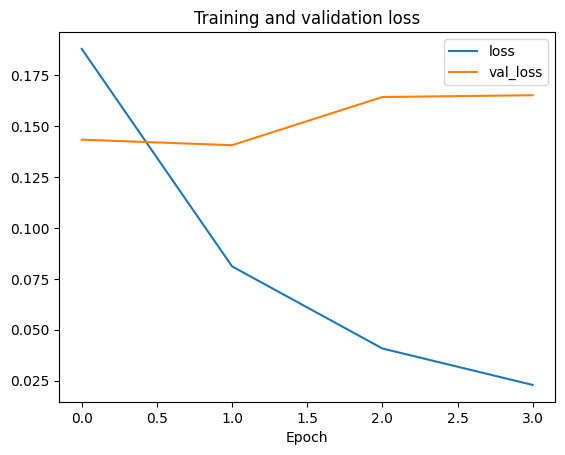

Validation: {'accuracy': 0.9513, 'precision': 0.9023, 'recall': 0.9545, 'f1': 0.9276}


In [7]:
class_weight = {0: len(y_train) / (2 * (y_train == 0).sum()),
                1: len(y_train) / (2 * (y_train == 1).sum())}
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=10, batch_size=64,
                    class_weight=class_weight, callbacks=[early_stop], verbose=2)

pd.DataFrame(history.history)[['loss', 'val_loss']].plot(title='Training and validation loss', xlabel='Epoch')
plt.show()
val_pred = (model.predict(X_val, batch_size=256, verbose=0).ravel() >= 0.5).astype(int)
print('Validation:', {k: round(v, 4) for k, v in compute_metrics(y_val, val_pred).items()})

## 7. Evaluate on the test partition

              precision    recall  f1-score   support

        Real     0.9739    0.9510    0.9623      4835
        Fake     0.9038    0.9477    0.9252      2350

    accuracy                         0.9499      7185
   macro avg     0.9389    0.9493    0.9438      7185
weighted avg     0.9510    0.9499    0.9502      7185



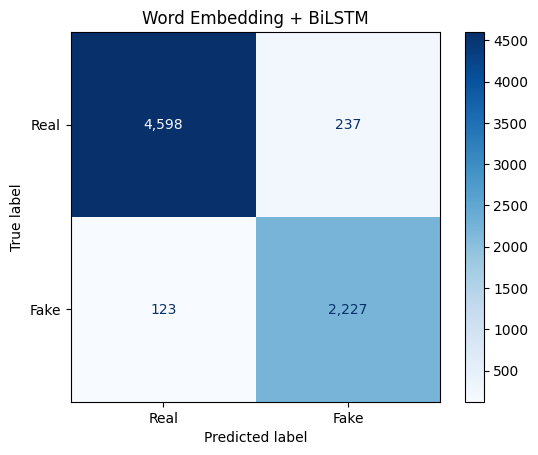

,0
accuracy,0.9499
precision,0.9038
recall,0.9477
f1,0.9252


In [8]:
test_pred = (model.predict(X_test, batch_size=256, verbose=0).ravel() >= 0.5).astype(int)
test_metrics = evaluate_on_test(test_pred, 'Word Embedding + BiLSTM')
pd.Series(test_metrics).round(4)

## Robustness check: how much of the score is real?
Read this table before quoting the headline score. IFND has two known weaknesses:

- **Synthetic rows:** about 60% of the fake rows have the source `AUGMENT`. They were generated from other fake headlines, so a test row can closely resemble a training row.
- **Giveaway words:** fake rows mostly come from fact-checking sites, so their headlines contain words like "fact check" or "viral". Those words identify the publisher's style, not whether a claim is false.

Lower scores in the last rows show how heavily the model relies on these patterns. The word list comes from inspecting the data, so treat this as an indicator rather than a precise measurement.

In [9]:
robustness = robustness_check(test_pred)
robustness

,rows,fake_rows,accuracy,precision,recall,f1
subset,,,,,,
All test headlines,7185,2350,0.9499,0.9038,0.9477,0.9252
Excluding synthetic (AUGMENT),5860,1025,0.9512,0.8046,0.9522,0.8722
Without giveaway words,5193,462,0.9397,0.6347,0.7597,0.6916
Neither synthetic nor giveaway,4922,191,0.9506,0.4261,0.7853,0.5525


## 8. Save results and try a headline

In [10]:
save_results(3, 'Word Embedding + BiLSTM', test_pred, test_metrics, robustness,
             {'vocab_size': VOCAB_SIZE, 'max_len': MAX_LEN, 'embedding_dim': 100, 'lstm_units': 64,
              'epochs_run': len(history.history['loss'])})
os.makedirs('models', exist_ok=True)
model.save('models/bilstm.keras')

def predict_headline(headline):
    x = to_padded([tokenize(repair_text(headline))])
    prob_fake = float(model.predict(x, verbose=0)[0, 0])
    return f"{'FAKE' if prob_fake >= 0.5 else 'REAL'} (probability of fake: {prob_fake:.2f})"

print(predict_headline('Supreme Court seeks response from Centre on new highway plea'))
print(predict_headline('Viral video claims the government will give free phones to all students'))

Saved to the results folder
REAL (probability of fake: 0.00)
FAKE (probability of fake: 1.00)


In [11]:
import os
import zipfile
from google.colab import files

zip_filename = 'project_data_and_results.zip'

with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    # 1. Add IFND.csv if it exists
    if os.path.exists('IFND.csv'):
        zipf.write('IFND.csv')
        print("Added IFND.csv to zip")

    # 2. Add files from the results/ directory
    if os.path.exists('results'):
        for root, dirs, filenames in os.walk('results'):
            for filename in filenames:
                filepath = os.path.join(root, filename)
                zipf.write(filepath, os.path.relpath(filepath, '.'))
        print("Added results folder to zip")

    # 3. Add files from the models/ directory
    if os.path.exists('models'):
        for root, dirs, filenames in os.walk('models'):
            for filename in filenames:
                filepath = os.path.join(root, filename)
                zipf.write(filepath, os.path.relpath(filepath, '.'))
        print("Added models folder to zip")

# Trigger the download
print("Downloading zip file...")
files.download(zip_filename)

Added IFND.csv to zip
Added results folder to zip
Added models folder to zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Upload to GitHub
1. Create the branch `student-3-bilstm` in the shared repository.
2. In Colab, choose **File > Save a copy in GitHub**, then select the repository and this branch.
3. Add `results/student_3_metrics.json` to the same branch using **Add file > Upload files** on GitHub.

Do not commit `IFND.csv` or saved model files. The dataset's authors allow research use only and ask users to cite: Sharma, D. K., & Garg, S. (2021). *IFND: a benchmark dataset for fake news detection.* Complex & Intelligent Systems.